## Olist E-Commerce: Data Exploration with DuckDB

## 1. Setup the notebook

In this notebook we load five tables of the e-commerce dataset into DuckDB and explore them with SQL before designing a data warehouse.

**What we will do**

1. Load the CSV files into DuckDB
2. Understand each table: structure, grain, keys
3. Check the relationships (foreign keys)
4. Find data quality issues
5. Build a star schema

**Tables:** `customers`, `orders`, `order_items`, `products`, `sellers`

In [1]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# works whether the notebook sits in the project root or in a subfolder
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WAREHOUSE_DIR = DATA_DIR / "warehouse"
csv = RAW_DIR / "olist_orders_dataset.csv"

In [3]:
print(duckdb.sql(f"SELECT count(*) FROM '{csv}'"))

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        99441 │
└──────────────┘



### DuckDB lets query CSV data with SQL. The database file persists locally so later notebooks can reuse the loaded raw tables.

In [4]:
WAREHOUSE_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = WAREHOUSE_DIR / "ecommerce.duckdb"
con = duckdb.connect(str(DB_PATH))

In [5]:
def q(sql_str: str) -> pd.DataFrame:
    """Run a SQL query in DuckDB and return a pandas DataFrame."""
    return con.sql(sql_str).df()

## 2. Load the source tables into a **raw schema**

A Schema is a namespace that groups tables. We keep the source copies in **raw**
so that they remain distinguishable from cleaned warehouse tables we will create later.

### Define a mapping to transform column types

In [6]:
RAW_TABLES: dict[str, dict[str, str]] = {
    "customers": {"customer_zip_code_prefix": "VARCHAR"},  # keep leading zeros
    "orders": {},
    "order_items": {},
    "products": {},
    "sellers": {}
}

### Define some helper functions

In [7]:
def csv_path(table: str) -> Path:
    """"""
    return RAW_DIR / f"olist_{table}_dataset.csv"

def check_source_files(tables) -> None:
    """Fail once, list every missing file"""
    missing = [csv_path(t) for t in tables if not csv_path(t).exists()]
    if missing:
        names = "\n".join(f" - {p}" for p in missing)
        raise FileNotFoundError(f"Missing CSV files: {names}")

#### Define schema name for source data

In [8]:
RAW_SCHEMA = "raw"

### Load data into source tables

In [9]:
def load_raw_table(con: duckdb.DuckDBPyConnection, table: str, column_types: dict[str, str]) -> int:
    target = f'{RAW_SCHEMA}."{table}"'
    source = con.read_csv(str(csv_path(table)), header=True, dtype=column_types or None)
    con.execute(f"DROP TABLE IF EXISTS {target}")
    source.to_table(target)
    return con.execute(f"SELECT count(*) FROM {target}").fetchone()[0]

### Sanity check if we have all required source files

In [10]:
check_source_files(RAW_TABLES)

### Create **RAW_SCHEMA** if it does not exist

In [11]:
con.execute(f"CREATE SCHEMA IF NOT EXISTS {RAW_SCHEMA}")

### Execute **load_raw_table** to load all source data

In [12]:
row_counts = {t: load_raw_table(con, t, types) for t, types in RAW_TABLES.items()}

### Check count of rows inserted into each `raw`.`<table>`

In [13]:
pd.DataFrame(row_counts.items(), columns=["table_name", "row_count"])

,table_name,row_count
0,customers,99441
1,orders,99441
2,order_items,112650
3,products,32951
4,sellers,3095


## 3. Look at each table

For every table we ask: **what does one row represent?** This is the *grain*. Getting the grain right is the most important step in dimensional modeling.

In [14]:
for t in RAW_TABLES:
    print(f"----- {t} -----")
    display(q(f"DESCRIBE raw.{t}")[["column_name", "column_type", "null"]])
    display(q(f"SELECT * FROM raw.{t} LIMIT 3"))

----- customers -----


,column_name,column_type,null
0,customer_id,VARCHAR,YES
1,customer_unique_id,VARCHAR,YES
2,customer_zip_code_prefix,VARCHAR,YES
3,customer_city,VARCHAR,YES
4,customer_state,VARCHAR,YES


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP


----- orders -----


,column_name,column_type,null
0,order_id,VARCHAR,YES
1,customer_id,VARCHAR,YES
2,order_status,VARCHAR,YES
3,order_purchase_timestamp,TIMESTAMP,YES
4,order_approved_at,TIMESTAMP,YES
5,order_delivered_carrier_date,TIMESTAMP,YES
6,order_delivered_customer_date,TIMESTAMP,YES
7,order_estimated_delivery_date,TIMESTAMP,YES


...

,column_name,column_type,null
0,product_id,VARCHAR,YES
1,product_category_name,VARCHAR,YES
2,product_name_lenght,BIGINT,YES
3,product_description_lenght,BIGINT,YES
4,product_photos_qty,BIGINT,YES
5,product_weight_g,BIGINT,YES
6,product_length_cm,BIGINT,YES
7,product_height_cm,BIGINT,YES
8,product_width_cm,BIGINT,YES


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15


----- sellers -----


,column_name,column_type,null
0,seller_id,VARCHAR,YES
1,seller_zip_code_prefix,VARCHAR,YES
2,seller_city,VARCHAR,YES
3,seller_state,VARCHAR,YES


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


`SUMMARIZE`profiles every column is one command: min, max, average, null percentage,
approximate distinct count.

In [15]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [16]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [17]:
q("SUMMARIZE raw.products")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,32951,0.00
1,product_category_name,VARCHAR,agro_industria_e_comercio,utilidades_domesticas,66,NaN,NaN,NaN,NaN,NaN,32951,1.85
2,product_name_lenght,BIGINT,5,76,64,48.47694876472589,10.245740725237287,42,51,57,32951,1.85
3,product_description_lenght,BIGINT,4,3992,2781,771.4952846232337,635.1152246349538,339,594,973,32951,1.85
4,product_photos_qty,BIGINT,1,20,20,2.1889861166939797,1.7367656379315435,1,1,3,32951,1.85
5,product_weight_g,BIGINT,0,40425,2155,2276.4724877841513,4282.038730977024,300,701,1883,32951,0.01
6,product_length_cm,BIGINT,7,105,97,30.81507784758263,16.914458054065953,18,25,39,32951,0.01
7,product_height_cm,BIGINT,2,105,99,16.937661234028347,13.637554061749569,8,13,21,32951,0.01
8,product_width_cm,BIGINT,6,118,92,23.196728277034204,12.079047453227794,15,20,30,32951,0.01


## 4. Primary Keys

A **primary key** uniquely identifies a row. A column is a valid candidate only if `count(*) = count(distinct ...)` and it has no nulls.

- A **composite key** uses several columns together (`order_items`)
- A **natural key** comes from the business (`customer_unique_id`).
- A **surrogate key** is generated by the warehouse (`customer_key = 1, 2, 3...`)

In [18]:
q("""
SELECT 'customers.customer_id'         AS candidate, count(*) AS n, count(DISTINCT customer_id) AS n_distinct FROM raw.customers
UNION ALL SELECT 'customers.customer_unique_id',         count(*), count(DISTINCT customer_unique_id) FROM raw.customers
UNION ALL SELECT 'orders.order_id',                      count(*), count(DISTINCT order_id) FROM raw.orders
UNION ALL SELECT 'order_items.order_id (alone)',         count(*), count(DISTINCT order_id) FROM raw.order_items
UNION ALL SELECT 'order_items(order_id, order_item_id)', count(*), count(DISTINCT (order_id, order_item_id)) FROM raw.order_items
UNION ALL SELECT 'products.product_id',                  count(*), count(DISTINCT product_id) FROM raw.products
UNION ALL SELECT 'sellers.seller_id',                    count(*), count(DISTINCT seller_id) FROM raw.sellers
""")

,candidate,n,n_distinct
0,customers.customer_id,99441,99441
1,customers.customer_unique_id,99441,96096
2,orders.order_id,99441,99441
3,order_items.order_id (alone),112650,98666
4,"order_items(order_id, order_item_id)",112650,112650
5,products.product_id,32951,32951
6,sellers.seller_id,3095,3095


## 4. Foreign key relationships

```
customers 1 ---- N orders 1 ---- N order_items N ---- 1 products
```

A foreign key is healthy when every value exists in the parent table. An **orphan** is
a child row with no parent.

In [19]:
q("""
SELECT 'orders without customer' AS check_name, count(*) AS n
  FROM raw.orders o ANTI JOIN raw.customers c USING (customer_id)
UNION ALL SELECT 'items without order', count(*)
  FROM raw.order_items i ANTI JOIN raw.orders o USING (order_id)
UNION ALL SELECT 'items without product', count(*)
  FROM raw.order_items i ANTI JOIN raw.products p USING (product_id)
UNION ALL SELECT 'items without seller', count(*)
    FROM raw.order_items i ANTI JOIN raw.sellers s USING (seller_id)
UNION ALL SELECT 'orders without items', count(*)
  FROM raw.orders o ANTI JOIN raw.order_items i USING (order_id)
""")

,check_name,n
0,orders without customer,0
1,items without order,0
2,items without product,0
3,items without seller,0
4,orders without items,775


No orphans in the child-to-parent direction. But 775 orders have no items. An **INNER JOIN** from orders
to items would silently remove them.

## 5. Data Quality

we check five dimensions: completeness(nulls), uniqueness, validity (values in a sensible range),
consistency (fields agree), timeliness (coverage)

### 5.1 Orders with no items

#### Exercise 1

In [20]:
q("""
SELECT o.order_status, count(*) AS orders_without_items
FROM raw.orders o
ANTI JOIN raw.order_items i USING (order_id)
GROUP BY o.order_status
ORDER BY orders_without_items DESC
""")

,order_status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


### 5.2 Check order status and class imbalance

#### Exercise 2

In [21]:
q("""
SELECT order_status,
       count(*) AS n,
       round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
FROM raw.orders
GROUP BY order_status
ORDER BY n DESC
""")

,order_status,n,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


### 5.3 Missing and inconsistent timestamps

#### Exercise 3

In [22]:
q("""
SELECT count(*) FILTER (WHERE order_approved_at IS NULL) AS approved_null,
       count(*) FILTER (WHERE order_delivered_carrier_date IS NULL) AS carrier_null,
       count(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS delivered_null,
       count(*) FILTER (WHERE order_status = 'delivered' AND order_delivered_customer_date IS NULL) AS delivered_but_no_date,
       count(*) FILTER (WHERE order_delivered_carrier_date > order_delivered_customer_date) AS carrier_after_customer
FROM raw.orders
""")

,approved_null,carrier_null,delivered_null,delivered_but_no_date,carrier_after_customer
0,160,1783,2965,8,23


### 5.4 Time coverage

#### Exercise 4

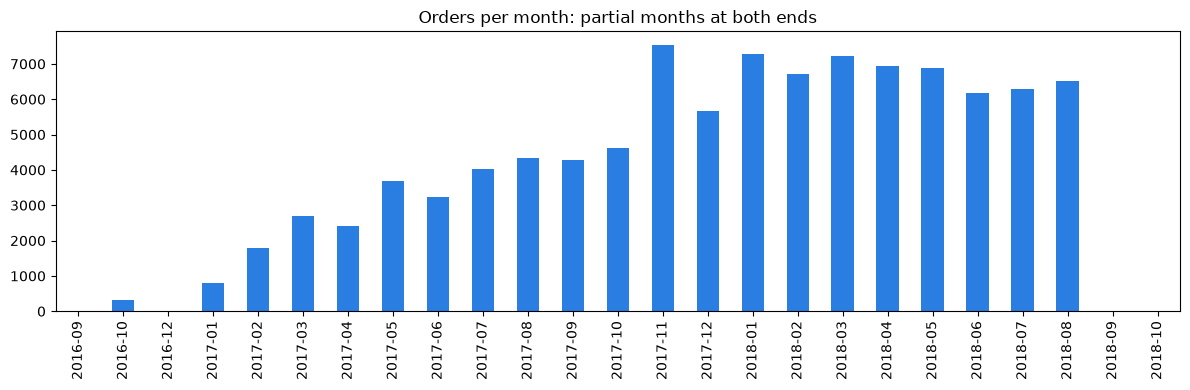

In [23]:
monthly = q("""
SELECT strftime(CAST(order_purchase_timestamp AS TIMESTAMP), '%Y-%m') AS month,
       count(*) AS orders
FROM raw.orders
GROUP BY 1
ORDER BY 1
""")
ax = monthly.plot.bar(x="month", y="orders", figsize=(12, 4), legend=False, color="#2a7de1")
ax.set_title("Orders per month: partial months at both ends")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 5.5 Product completeness check

#### Exercise 5

In [24]:
q("""
SELECT count(*) AS products,
       count(*) FILTER (WHERE product_category_name IS NULL) AS category_null,
       count(*) FILTER (WHERE product_weight_g IS NULL) AS weight_null,
       count(*) FILTER (WHERE product_weight_g = 0) AS weight_zero,
       count(DISTINCT product_category_name) AS n_categories
FROM raw.products
""")

,products,category_null,weight_null,weight_zero,n_categories
0,32951,610,2,4,73


## 6. Keys, Cardinality, ERD

### 6.1 Grain

| Table | One row represents |
|---|---|
| `customers` | one `customer_id`, i.e. the customer record attached to one order |
| `orders` | one order |
| `order_items` | one item line inside one order |
| `products` | one product |
| `sellers` | one seller |



### 6.2 Primary keys: rows = distinct values, and no nulls

In [25]:
pk = q("""
SELECT 'customers' AS tbl, 'customer_id' AS candidate,
       count(*) AS n, count(DISTINCT customer_id) AS n_distinct,
       count(*) FILTER (WHERE customer_id IS NULL) AS n_null
FROM raw.customers
UNION ALL
SELECT 'customers', 'customer_unique_id',
       count(*), count(DISTINCT customer_unique_id),
       count(*) FILTER (WHERE customer_unique_id IS NULL)
FROM raw.customers
UNION ALL
SELECT 'orders', 'order_id',
       count(*), count(DISTINCT order_id),
       count(*) FILTER (WHERE order_id IS NULL)
FROM raw.orders
UNION ALL
SELECT 'order_items', 'order_id (alone)',
       count(*), count(DISTINCT order_id),
       count(*) FILTER (WHERE order_id IS NULL)
FROM raw.order_items
UNION ALL
SELECT 'order_items', '(order_id, order_item_id)',
       count(*), count(DISTINCT (order_id, order_item_id)),
       count(*) FILTER (WHERE order_id IS NULL OR order_item_id IS NULL)
FROM raw.order_items
UNION ALL
SELECT 'products', 'product_id',
       count(*), count(DISTINCT product_id),
       count(*) FILTER (WHERE product_id IS NULL)
FROM raw.products
UNION ALL
SELECT 'sellers', 'seller_id',
       count(*), count(DISTINCT seller_id),
       count(*) FILTER (WHERE seller_id IS NULL)
FROM raw.sellers
""")
pk["is_valid_key"] = (pk["n"] == pk["n_distinct"]) & (pk["n_null"] == 0)
pk

,tbl,candidate,n,n_distinct,n_null,is_valid_key
0,customers,customer_id,99441,99441,0,True
1,customers,customer_unique_id,99441,96096,0,False
2,orders,order_id,99441,99441,0,True
3,order_items,order_id (alone),112650,98666,0,False
4,order_items,"(order_id, order_item_id)",112650,112650,0,True
5,products,product_id,32951,32951,0,True
6,sellers,seller_id,3095,3095,0,True


A candidate is a valid primary key only when `is_valid_key` is `True`.
`customers.customer_unique_id` and `order_items.order_id (alone)` should be **False**: that is exactly why
`customer_id` is the key of `customers` and why `order_items` needs the two-column key.

### 6.3 Foreign keys: orphan check with ANTI JOIN, plus null check

In [26]:
fk = q("""
SELECT 'customers' AS parent, 'orders' AS child, 'customer_id' AS fk_column,
       (SELECT count(*) FROM raw.orders c ANTI JOIN raw.customers p USING (customer_id)) AS orphans,
       (SELECT count(*) FROM raw.orders WHERE customer_id IS NULL) AS null_fk
UNION ALL
SELECT 'orders', 'order_items', 'order_id',
       (SELECT count(*) FROM raw.order_items c ANTI JOIN raw.orders p USING (order_id)),
       (SELECT count(*) FROM raw.order_items WHERE order_id IS NULL)
UNION ALL
SELECT 'products', 'order_items', 'product_id',
       (SELECT count(*) FROM raw.order_items c ANTI JOIN raw.products p USING (product_id)),
       (SELECT count(*) FROM raw.order_items WHERE product_id IS NULL)
UNION ALL
SELECT 'sellers', 'order_items', 'seller_id',
       (SELECT count(*) FROM raw.order_items c ANTI JOIN raw.sellers p USING (seller_id)),
       (SELECT count(*) FROM raw.order_items WHERE seller_id IS NULL)
""")
fk

,parent,child,fk_column,orphans,null_fk
0,customers,orders,customer_id,0,0
1,orders,order_items,order_id,0,0
2,products,order_items,product_id,0,0
3,sellers,order_items,seller_id,0,0


### 6.4 Cardinality: min and max child rows per parent

In [27]:
card = q("""
SELECT 'customers' AS parent, 'orders' AS child, min(n) AS min_children, max(n) AS max_children
FROM (SELECT p.customer_id, count(c.order_id) AS n
      FROM raw.customers p LEFT JOIN raw.orders c ON c.customer_id = p.customer_id
      GROUP BY p.customer_id)
UNION ALL
SELECT 'orders', 'order_items', min(n), max(n)
FROM (SELECT p.order_id, count(c.order_item_id) AS n
      FROM raw.orders p LEFT JOIN raw.order_items c ON c.order_id = p.order_id
      GROUP BY p.order_id)
UNION ALL
SELECT 'products', 'order_items', min(n), max(n)
FROM (SELECT p.product_id, count(c.order_id) AS n
      FROM raw.products p LEFT JOIN raw.order_items c ON c.product_id = p.product_id
      GROUP BY p.product_id)
UNION ALL
SELECT 'sellers', 'order_items', min(n), max(n)
FROM (SELECT p.seller_id, count(c.order_id) AS n
      FROM raw.sellers p LEFT JOIN raw.order_items c ON c.seller_id = p.seller_id
      GROUP BY p.seller_id)
""")
card

,parent,child,min_children,max_children
0,customers,orders,1,1
1,orders,order_items,0,21
2,products,order_items,1,527
3,sellers,order_items,1,2033


### 6.5 From data to diagram symbols

In [28]:
VERBS = {("customers", "orders"): "places",
         ("orders", "order_items"): "contains",
         ("products", "order_items"): "appears in",
         ("sellers", "order_items"): "sells"}

rel = fk.merge(card, on=["parent", "child"])
rel["verb"] = [VERBS[(p, c)] for p, c in zip(rel["parent"], rel["child"])]
rel["parent_end"] = ["exactly_one" if (o == 0 and n == 0) else "zero_one"
                     for o, n in zip(rel["orphans"], rel["null_fk"])]
rel["child_end"] = ["zero_many" if m == 0 else "one_many" for m in rel["min_children"]]
rel["data_stricter_max"] = rel["max_children"] == 1      # data says "one", diagram says "many"
rel["circle_justified"] = rel["min_children"] == 0       # data really has parents without children
rel[["parent", "child", "verb", "fk_column", "min_children", "max_children",
     "parent_end", "child_end", "data_stricter_max", "circle_justified"]]

,parent,child,verb,fk_column,min_children,max_children,parent_end,child_end,data_stricter_max,circle_justified
0,customers,orders,places,customer_id,1,1,exactly_one,one_many,True,False
1,orders,order_items,contains,order_id,0,21,exactly_one,zero_many,False,True
2,products,order_items,appears in,product_id,1,527,exactly_one,one_many,False,False
3,sellers,order_items,sells,seller_id,1,2033,exactly_one,one_many,False,False


### 6.6 Draw the ERD (crow's foot) and save it

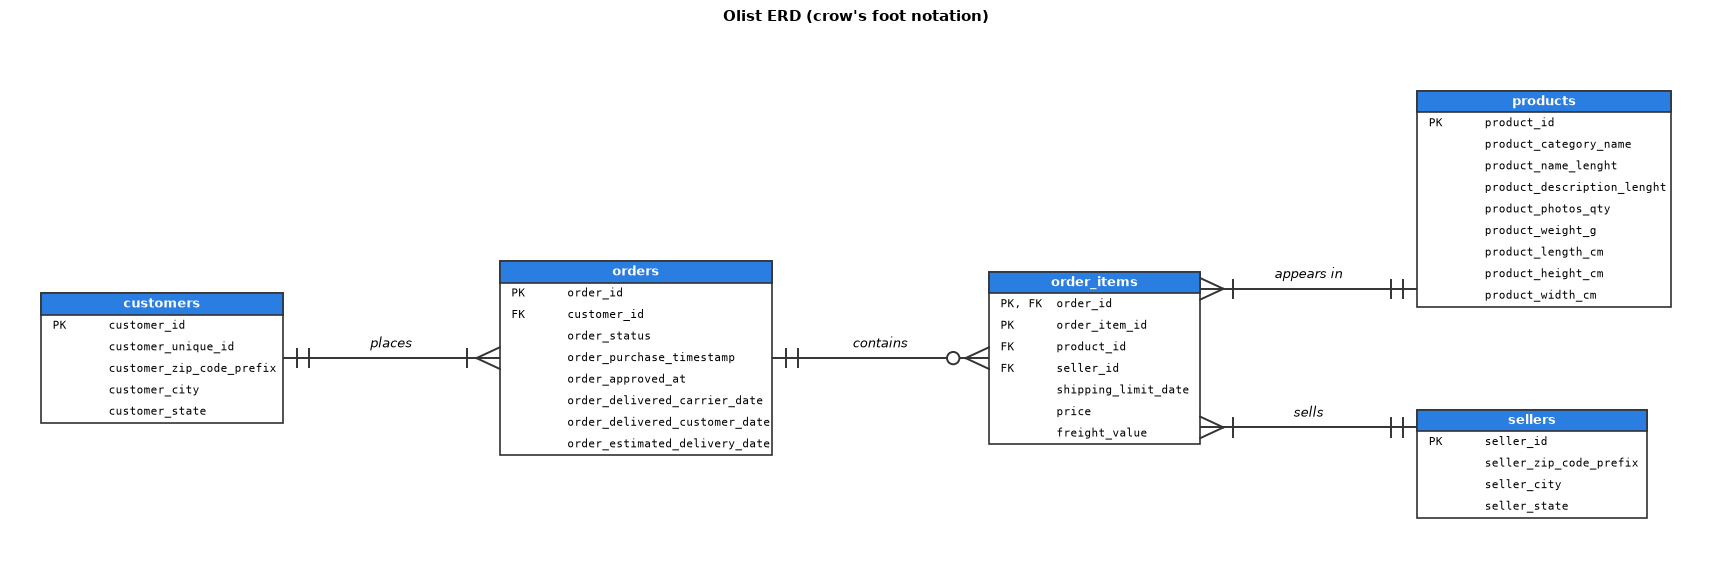

Saved: C:\Users\assef\kddm_lab\erd.png and C:\Users\assef\kddm_lab\erd.pdf


In [29]:
from matplotlib.patches import Rectangle, Circle

PK_COLS = {"customers": ["customer_id"],
           "orders": ["order_id"],
           "order_items": ["order_id", "order_item_id"],   # composite key: tag BOTH columns
           "products": ["product_id"],
           "sellers": ["seller_id"]}
FK_COLS = {"orders": ["customer_id"],
           "order_items": ["order_id", "product_id", "seller_id"]}

ROW_H, CHAR_W, GAP = 0.28, 0.0785, 2.8     # inches (monospace 8pt)

def table_rows(t):
    rows = []
    for col in q(f"DESCRIBE raw.{t}")["column_name"]:
        tags = []
        if col in PK_COLS.get(t, []): tags.append("PK")
        if col in FK_COLS.get(t, []): tags.append("FK")
        rows.append(f"{', '.join(tags):<8}{col}")
    return rows

TABLES = ["customers", "orders", "order_items", "products", "sellers"]
rows = {t: table_rows(t) for t in TABLES}
width = {t: max(len(t) + 2, max(len(r) for r in rows[t]) + 2) * CHAR_W + 0.45 for t in TABLES}
height = {t: (len(rows[t]) + 1) * ROW_H for t in TABLES}

# x positions (left edge)
X = {}
X["customers"] = 0.4
X["orders"] = X["customers"] + width["customers"] + GAP
X["order_items"] = X["orders"] + width["orders"] + GAP
X["products"] = X["sellers"] = X["order_items"] + width["order_items"] + GAP

# y positions (top edge), order_items is the anchor
items_top = 0.0
items_bottom = items_top - height["order_items"]
yc = (items_top + items_bottom) / 2
TOP = {"order_items": items_top,
       "customers": yc + height["customers"] / 2,
       "orders": yc + height["orders"] / 2,
       "products": items_top - 0.45 + height["products"],
       "sellers": items_bottom + 0.45}
ymin = min(TOP[t] - height[t] for t in TABLES)
ymax = max(TOP.values())
shift = 0.5 - ymin
TOP = {t: v + shift for t, v in TOP.items()}
items_top += shift; items_bottom += shift; yc += shift
fig_w = X["products"] + max(width["products"], width["sellers"]) + 0.4
fig_h = ymax + shift + 0.8

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_xlim(0, fig_w); ax.set_ylim(0, fig_h); ax.axis("off")

for t in TABLES:
    x, top, w, h = X[t], TOP[t], width[t], height[t]
    ax.add_patch(Rectangle((x, top - h), w, h, fc="white", ec="#333", lw=1.2, zorder=2))
    ax.add_patch(Rectangle((x, top - ROW_H), w, ROW_H, fc="#2a7de1", ec="#333", lw=1.2, zorder=3))
    ax.text(x + w / 2, top - ROW_H / 2, t, ha="center", va="center", color="white",
            fontsize=9, fontweight="bold", zorder=4)
    for i, r in enumerate(rows[t]):
        ax.text(x + 0.15, top - ROW_H * (i + 1.5), r, ha="left", va="center",
                family="monospace", fontsize=8, zorder=4)

def end_symbol(px, py, dx, kind):
    """Draw a crow's foot symbol at box edge (px, py); (dx, 0) points toward the other table."""
    def bar(d):  ax.plot([px + dx * d] * 2, [py - 0.12, py + 0.12], color="#333", lw=1.4, zorder=5)
    def circ(d): ax.add_patch(Circle((px + dx * d, py), 0.08, fc="white", ec="#333", lw=1.4, zorder=6))
    def crow(apex):
        for s in (-1, 1):
            ax.plot([px + dx * apex, px], [py, py + s * 0.14], color="#333", lw=1.4, zorder=5)
    if kind == "exactly_one": bar(0.18); bar(0.34)
    elif kind == "zero_one":  bar(0.18); circ(0.38)
    elif kind == "one_many":  crow(0.30); bar(0.42)
    elif kind == "zero_many": crow(0.30); circ(0.46)

LINE_Y = {("customers", "orders"): yc,
          ("orders", "order_items"): yc,
          ("products", "order_items"): items_top - 0.22,
          ("sellers", "order_items"): items_bottom + 0.22}

for _, r in rel.iterrows():
    p, c, y = r["parent"], r["child"], LINE_Y[(r["parent"], r["child"])]
    if X[p] < X[c]:
        px, cx, pdx, cdx = X[p] + width[p], X[c], 1, -1
    else:
        px, cx, pdx, cdx = X[p], X[c] + width[c], -1, 1
    ax.plot([px, cx], [y, y], color="#333", lw=1.4, zorder=1)
    end_symbol(px, y, pdx, r["parent_end"])
    end_symbol(cx, y, cdx, r["child_end"])
    ax.text((px + cx) / 2, y + 0.1, r["verb"], ha="center", va="bottom", fontsize=9, style="italic")

ax.set_title("Olist ERD (crow's foot notation)", fontsize=11, fontweight="bold")
fig.savefig(ROOT / "erd.png", dpi=200, bbox_inches="tight")
fig.savefig(ROOT / "erd.pdf", bbox_inches="tight")
plt.show()
print("Saved:", ROOT / "erd.png", "and", ROOT / "erd.pdf")